In [22]:
# SETUP, run EVERYTIME a new session is started
from google.colab import drive, userdata
drive.mount('/content/drive')
PROJECT = "/content/drive/MyDrive/MMA3001/MMA3001_Project"
try:
    AUTH = f"oauth2:{userdata.get('GH_PAT')}@"   # only needed to push
except Exception:
    AUTH = ""                                   # no secret: read-only clone

import os, sys
%cd /content
if not os.path.isdir("/content/repo"):
                %cd /content
if not os.path.isdir("/content/repo"):
    !git clone -q https://{AUTH}github.com/Ryan-T-Monash/MMA3001-Project.git repo
    if not os.path.isdir("/content/repo"):
      !git clone -q https://{AUTH}github.com/Ryan-T-Monash/MMA3001-Project.git repo
else:
    !git -C /content/repo pull -q origin main
%cd /content/repo
!git config user.name "John"
!git config user.email "JohnSmith@..."
!pip install -q -r requirements.txt
sys.path.append("/content/repo/src")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content
/content/repo


In [2]:
# ---- Colab cell 2: settings (all tunable parameters live here) ----
# Noise filtering: trailing-mean window in snapshots (1 = raw, 6 = 1 hour)
SMOOTH = [1, 6, 24, 96]
# Model flexibility, each chosen on validation data
DEPTHS = [1, 2, 3, 4, 6, 8, 12]            # decision tree max_depth
SVR_C = [1, 10, 100, 1000]                 # SVR penalty
EXTRAP_HOURS = [2, 5, 10, 20, 40]          # trend-extrapolation fitting window
FAIL_FACTORS = [2, 3, 5]                   # failure threshold = factor x healthy RMS
# Splits: train / validation / test ratio (as in week 5.5), and seeds for the random block split
RATIO = (0.6, 0.2, 0.2)
SEEDS = [0, 1, 2, 3, 4]
BLOCK_HOURS, GAP_HOURS = 5, 1
# Catalogue baseline: Rexnord ZA-2115, C = 28 890 lb
LOAD_LB, RPM = 6000, 2000

In [3]:
# ---- Colab cell 3: load test 2 bearing 1 and build the features once ----
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rul_models import (catalogue_life_hours, life_at_reliability, failure_probability,
                        catalogue_rul, trailing_mean, extrapolate_rul_fast, candidate_models,
                        complexity_curve, tune_and_test, tune_fixed,
                        validation_curve, fixed_validation_curve)
from splits import time_split, interleaved_split, block_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

import glob                                # feature cache from the features cell (repo or Drive)
found = (glob.glob("/content/repo/data/features_2nd_test.csv")
         + glob.glob("/content/drive/MyDrive/MMA3001/MMA3001_Project/**/features_2nd_test.csv",
                     recursive=True))
print("features file:", found)
feat = pd.read_csv(found[0], index_col=0)
print(feat.tail(3)[["file", "rms_1", "kurtosis_1"]])   # last file can be near-empty (NaN)
lab = feat.dropna()
hours = lab.index.to_numpy() * 10 / 60     # test 2 snapshots are 10 min apart
rul = hours[-1] - hours                    # hours left until the last snapshot (failure)
rms, kurt = lab["rms_1"].to_numpy(), lab["kurtosis_1"].to_numpy()
healthy_rms = rms[:100].mean()             # first ~17 h assumed healthy

# Backward-looking smoothing only, so no future snapshot leaks into a feature
features = {sw: np.column_stack([trailing_mean(rms, sw), trailing_mean(kurt, sw)])
            for sw in SMOOTH}
print(f"{len(hours)} snapshots over {hours[-1]:.1f} h")

features file: ['/content/repo/data/features_2nd_test.csv', '/content/drive/MyDrive/MMA3001/MMA3001_Project/features_2nd_test.csv']
                       file     rms_1  kurtosis_1
sample                                           
981     2004.02.19.06.02.39  0.483835    7.891755
982     2004.02.19.06.12.39  0.002103    6.637513
983     2004.02.19.06.22.39  0.001533    1.390226
984 snapshots over 163.8 h


L10 = 1571 h, L50 = 5515 h, actual life = 164 h
Catalogue chance of failing this early: 0.35 %


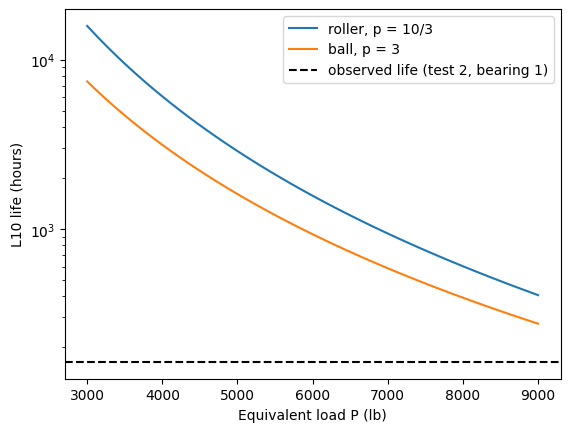

In [4]:
# ---- Colab cell 4: baseline, catalogue rating life (no sensor data) ----
# In plain words: this is what the manufacturer's catalogue promises, without looking
# at any vibration data, like the "service every 10 000 km" sticker on a car.
# L10 is the life that 90 % of identical bearings outlast; L50 is the life half outlast.
# We compare that promise with the 164 h this bearing actually lasted. The plot shows how
# much the promise depends on the load we assume: life goes as (C/P)^(10/3), so doubling
# the load cuts life about tenfold. Every model has to beat this to be worth using.
L10 = catalogue_life_hours(P=LOAD_LB, rpm=RPM)
L50 = life_at_reliability(L10, 0.5)
print(f"L10 = {L10:.0f} h, L50 = {L50:.0f} h, actual life = {hours[-1]:.0f} h")
print(f"Catalogue chance of failing this early: {100 * failure_probability(hours[-1], L10):.2f} %")

P = np.linspace(3000, 9000, 50)            # sensitivity to the assumed load and exponent
plt.semilogy(P, catalogue_life_hours(P=P, rpm=RPM), label="roller, p = 10/3")
plt.semilogy(P, catalogue_life_hours(P=P, rpm=RPM, p=3), label="ball, p = 3")
plt.axhline(hours[-1], color="k", ls="--", label="observed life (test 2, bearing 1)")
plt.xlabel("Equivalent load P (lb)")
plt.ylabel("L10 life (hours)")
plt.legend()
plt.show()

In [5]:
# ---- Colab cell 5: trend-extrapolation predictions for every setting, computed once ----
# In plain words: like watching a fuel gauge and guessing when it hits empty. At each
# moment, draw a straight line through the last few hours of vibration RMS and see when
# that line reaches the "failed" level. Only past data is used.
# Settings: how many hours of history to fit (short = jumpy, chases the noise; long =
# slow to notice the bearing getting worse), the failed level (2, 3 or 5 x healthy RMS)
# and how much the RMS is smoothed first. Nothing is learned from training data, so all
# 60 combinations are worked out once here; each split later picks the combination that
# does best on its own validation part.
# They depend only on past data, not on the split, so each split just scores them.
# extrapolate_rul_fast gives the same numbers as extrapolate_rul (checked in the tests)
# about 100x faster; the comparison is in the performance cells.
start = time.perf_counter()
extrap = {(sw, w, f): extrapolate_rul_fast(hours, trailing_mean(rms, sw), f * healthy_rms, w)
          for sw in SMOOTH for w in EXTRAP_HOURS for f in FAIL_FACTORS}
extrap_ms = 1000 * (time.perf_counter() - start) / len(extrap)   # per setting, for cell 12
print(f"{len(extrap)} extrapolation settings in {time.perf_counter() - start:.2f} s")
catalogue = {"L10": catalogue_rul(hours, L10), "L50": catalogue_rul(hours, L50)}


60 extrapolation settings in 0.02 s


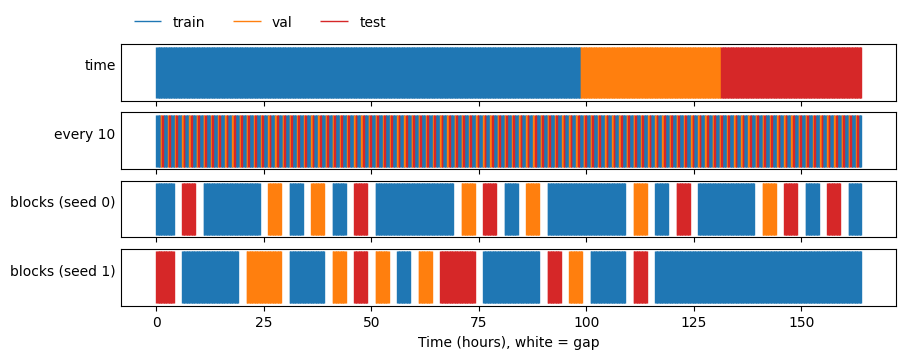

In [6]:
# ---- Colab cell 6: build every split and look at them ----
splits = [("time", None, time_split(len(hours), RATIO)),            # (method, seed, roles)
          ("every 10", None, interleaved_split(len(hours), RATIO, period=10))]
for s in SEEDS:
    splits.append(("blocks", s, block_split(hours, RATIO, BLOCK_HOURS, GAP_HOURS, s)))

# Blocks split, in plain words: cut the 164 h run into 5-hour chunks, shuffle the
# chunks like cards and deal 60 % to training, 20 % to validation and 20 % to test.
# Each chunk stays whole, so neighbouring snapshots (10 min apart, almost identical)
# end up on the same side. A 1-hour gap is left wherever two roles meet, so the
# model is never tested on a snapshot sitting right next to one it trained on.
# Different seeds deal the cards differently, hence the spread in the results.
colours = {"train": "tab:blue", "val": "tab:orange", "test": "tab:red"}
show = [sp for sp in splits if sp[1] in (None, 0, 1)]
fig, axes = plt.subplots(len(show), 1, figsize=(10, 0.6 * len(show) + 1), sharex=True)
for ax, (method, s, roles) in zip(axes, show):
    for role, c in colours.items():          # one thin bar per snapshot; gaps stay white
        ax.vlines(hours[roles == role], 0, 1, color=c, lw=1, label=role)
    ax.set_yticks([])
    ax.set_ylabel(method if s is None else f"{method} (seed {s})", rotation=0, ha="right")
axes[0].legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.05), frameon=False)
axes[-1].set_xlabel("Time (hours), white = gap")
plt.show()

In [7]:
# ---- Colab cell 7: tune on validation, score once on test, for every split ----
# In plain words: the fair exam. For every split, each model tries all of its settings
# (smoothing window, tree depth, SVR C), learning from the training part and being
# marked on the validation part. Only the best setting then sits the test, once.
# The catalogue L10/L50 have nothing to tune, so they are just marked on the test part.
# The Dummy predicts the average remaining life seen in training for every snapshot:
# the "know nothing" benchmark. The result is one row per model per split.
models = {
    "mean (Dummy)": (lambda: DummyRegressor(), [{"smooth": 1}]),
    "linear": (lambda: make_pipeline(StandardScaler(), LinearRegression()),
               [{"smooth": sw} for sw in SMOOTH]),
    "tree": (lambda max_depth: DecisionTreeRegressor(max_depth=max_depth, random_state=0),
             [{"smooth": sw, "max_depth": d} for sw in SMOOTH for d in DEPTHS]),
    "SVR": (lambda C: make_pipeline(StandardScaler(), SVR(C=C, epsilon=1.0)),
            [{"smooth": sw, "C": c} for sw in SMOOTH for c in SVR_C]),
}

rows, preds = [], {}
start = time.perf_counter()
for method, s, roles in splits:
    split_id = {"method": method, "seed": s}
    for name, life in catalogue.items():   # baseline: nothing to tune, used as published
        row, p = tune_fixed({name: life}, rul, roles, cap=False)
        rows.append({**split_id, "model": f"catalogue {name}", **row})
    row, p = tune_fixed(extrap, rul, roles)
    rows.append({**split_id, "model": "trend extrapolation", **row})
    preds[(method, s, "trend extrapolation")] = p
    for name, (make, grid) in models.items():
        row, p = tune_and_test(make, grid, features, rul, roles)
        rows.append({**split_id, "model": name, **row})
        preds[(method, s, name)] = p
results = pd.DataFrame(rows)
print(f"{len(splits)} splits x {results['model'].nunique()} models in "
      f"{time.perf_counter() - start:.1f} s")
results.round(2).head(10)

7 splits x 7 models in 3.2 s


,method,seed,model,settings,val_MAE_h,MAE_h,RMSE_h,late_%,smooth,train_MAE_h,max_depth,C
0,time,NaN,catalogue L10,L10,1407.03,1407.03,1407.03,100.00,NaN,NaN,NaN,NaN
1,time,NaN,catalogue L50,L50,5351.50,5351.50,5351.50,100.00,NaN,NaN,NaN,NaN
2,time,NaN,trend extrapolation,"(6, 20, 2)",16.97,50.96,78.07,33.67,NaN,NaN,NaN,NaN
3,time,NaN,mean (Dummy),NaN,65.67,98.33,98.78,100.00,1.0,24.67,NaN,NaN
4,time,NaN,linear,NaN,23.10,14.76,22.51,7.14,1.0,19.70,NaN,NaN
5,time,NaN,tree,NaN,16.42,49.08,49.98,100.00,24.0,4.06,8.0,NaN
6,time,NaN,SVR,NaN,43.01,79.83,80.38,100.00,1.0,18.81,NaN,10.0
7,every 10,NaN,catalogue L10,L10,1407.03,1407.03,1407.03,100.00,NaN,NaN,NaN,NaN
8,every 10,NaN,catalogue L50,L50,5351.50,5351.50,5351.50,100.00,NaN,NaN,NaN,NaN
9,every 10,NaN,trend extrapolation,"(1, 40, 2)",41.31,40.86,51.25,72.45,NaN,NaN,NaN,NaN


mean                     std
method               blocks every 10    time blocks
model                                              
SVR                     7.8      3.9    79.8    3.9
catalogue L10        1407.0   1407.0  1407.0    0.0
catalogue L50        5351.5   5351.5  5351.5    0.0
linear                 30.1     21.6    14.8    6.9
mean (Dummy)           47.1     40.8    98.3   11.6
tree                    7.9      1.9    49.1    1.0
trend extrapolation    43.1     40.9    51.0   17.2

method,blocks,every 10,time
model,,,
SVR,37.0,48.0,100.0
catalogue L10,100.0,100.0,100.0
catalogue L50,100.0,100.0,100.0
linear,46.0,53.0,7.0
mean (Dummy),32.0,50.0,100.0
tree,33.0,28.0,100.0
trend extrapolation,74.0,72.0,34.0


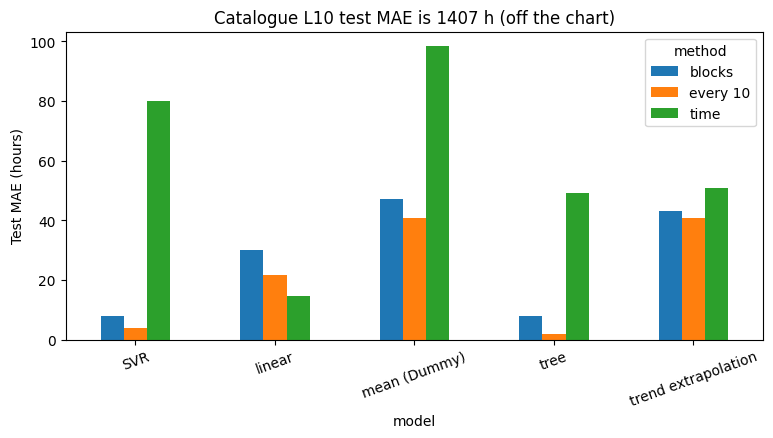

In [8]:
# ---- Colab cell 8: compare split methods against the baseline ----
# In plain words: the report card. The first table gives each model's test error
# (MAE, hours) for each split method. For "blocks" it is the average over the five seeds,
# and "std" shows how much it swings between seeds: a model whose score swings a lot is
# less trustworthy ("time" and "every 20" have one split each, so no std). "% late" is how often
# a model said the bearing had more life left than it really did: the dangerous mistake.
# Expect "every 20" to look best (it is leaky), "time" worst (it must predict a failure it
# never saw) and "blocks" in between. The catalogue rows are left off the bar chart
# because their ~1400 h error would squash everything else.
summary = results.pivot_table(index="model", columns="method", values="MAE_h",
                              aggfunc=["mean", "std"]).round(1)
display(summary)
display(results.pivot_table(index="model", columns="method", values="late_%").round(0))

mean_mae = results.pivot_table(index="model", columns="method", values="MAE_h")
mean_mae.drop(index=["catalogue L10", "catalogue L50"]).plot.bar(figsize=(9, 4))
plt.ylabel("Test MAE (hours)")
plt.title(f"Catalogue L10 test MAE is {mean_mae.loc['catalogue L10'].mean():.0f} h (off the chart)")
plt.xticks(rotation=20)
plt.show()

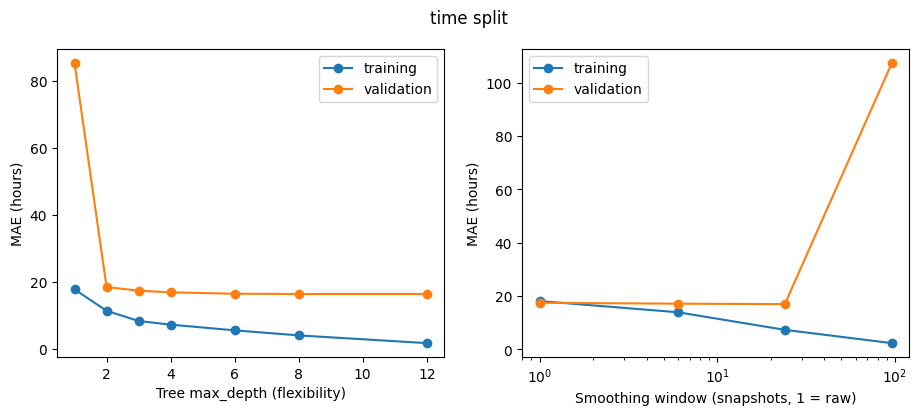

In [9]:
# ---- Colab cell 9: overfitting, training vs validation error (week 3.2) ----
# In plain words: the overfitting picture. Left: as the tree gets deeper (more flexible)
# its training error keeps falling, because it can memorise the training snapshots, but
# validation error stops improving or rises: that is overfitting. The best depth is where
# validation error is lowest. Right: the same idea for noise filtering (tree depth fixed
# at 4). Window 1 is the raw data, so the model learns the noise; very long windows blur
# the signal so the model reacts late. Change splits[0] to look at another split.
method, s, roles = splits[0]                          # time split; splits[1] = every 10, [2:] = blocks
tr, va = roles == "train", roles == "val"
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
X = features[24]
depth_curve = complexity_curve(lambda d: DecisionTreeRegressor(max_depth=d, random_state=0),
                               DEPTHS, X[tr], rul[tr], X[va], rul[va])
axes[0].plot(depth_curve.index, depth_curve["train_MAE_h"], "o-", label="training")
axes[0].plot(depth_curve.index, depth_curve["test_MAE_h"], "o-", label="validation")
axes[0].set_xlabel("Tree max_depth (flexibility)")
smooth_curve = pd.concat([complexity_curve(lambda _: DecisionTreeRegressor(max_depth=4, random_state=0),
                                           [sw], features[sw][tr], rul[tr], features[sw][va], rul[va])
                          for sw in SMOOTH])
axes[1].plot(smooth_curve.index, smooth_curve["train_MAE_h"], "o-", label="training")
axes[1].plot(smooth_curve.index, smooth_curve["test_MAE_h"], "o-", label="validation")
axes[1].set_xscale("log")
axes[1].set_xlabel("Smoothing window (snapshots, 1 = raw)")
for ax in axes:
    ax.set_ylabel("MAE (hours)")
    ax.legend()
fig.suptitle(f"{method} split")
plt.show()

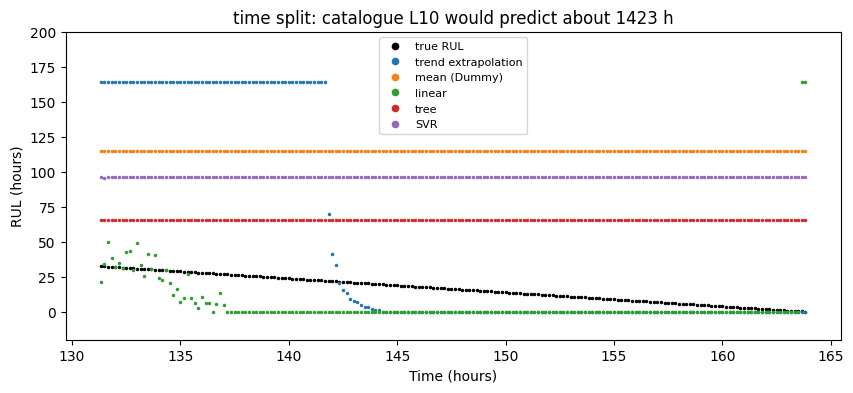

In [10]:
# ---- Colab cell 10: predicted vs true RUL on the test part of one split ----
# In plain words: the predictions against the truth on the test part of one split.
# Black dots are the true remaining life, falling steadily to zero at failure. A good
# model's dots sit on the black line. Dots above it are late (unsafe: the bearing fails
# before the planned replacement); dots below are early (safe but wasteful). The
# catalogue L10 is not drawn because it sits about 1400 h above the chart.
# Every prediction is clipped to 0 .. longest training RUL, because RUL cannot be
# negative. The results table is saved to data/ so it can be committed with the notebook.
method, s, roles = splits[0]                          # change the index to view another split
te = roles == "test"
plt.figure(figsize=(10, 4))
plt.plot(hours[te], rul[te], "k.", ms=3, label="true RUL")
for name in ["trend extrapolation", "mean (Dummy)", "linear", "tree", "SVR"]:
    plt.plot(hours[te], preds[(method, s, name)], ".", ms=3, label=name)
plt.ylim(-20, 200)                         # predictions are clipped to 0 .. longest training RUL
plt.xlabel("Time (hours)")
plt.ylabel("RUL (hours)")
plt.title(f"{method} split: catalogue L10 would predict about {L10 - hours[te].mean():.0f} h")
plt.legend(fontsize=8, markerscale=3)
plt.show()
import os
os.makedirs("/content/repo/data", exist_ok=True)
results.to_csv("/content/repo/data/rul_results_2nd_test.csv", index=False)


/tmp/ipykernel_64518/3741685889.py:19: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  curves["seed"] = curves["seed"].fillna(-1)          # time / every 10 have no seed


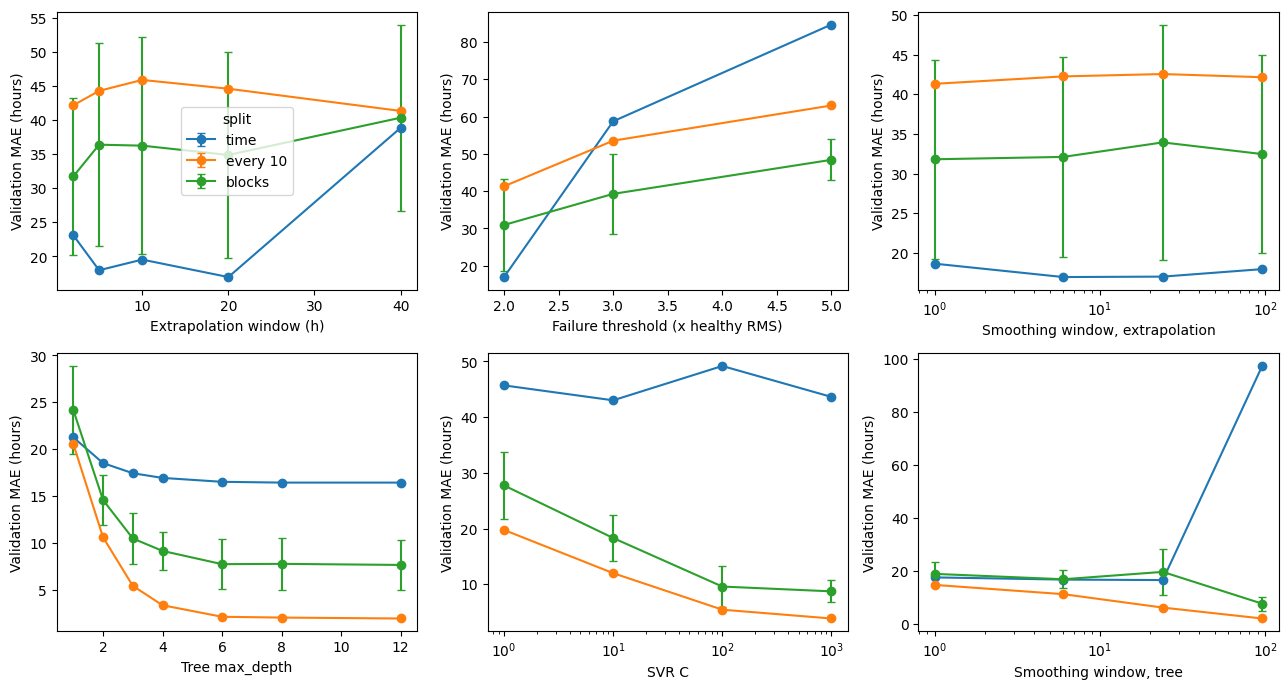

In [11]:
# ---- Colab cell 11: sensitivity, validation error for every setting (brief sections 4-6) ----
# In plain words: how much does each knob matter? For every split, every setting of every
# model is scored on the validation part (the test part is not touched). Each panel varies
# one knob; for each value the other knobs are set to their best, and the line is the
# average over the splits of that method (error bars = spread over the 5 block seeds).
# A flat line means the model is not sensitive to that knob (robust); a sharp dip means it
# has to be tuned carefully. A U-shape is the week 3.2 overfitting picture: too little
# smoothing or too much flexibility follows the noise, too much makes the model sluggish.
from rul_models import validation_curve, fixed_validation_curve

curves = []
for method, s, roles in splits:
    c = fixed_validation_curve(extrap, rul, roles, ["smooth", "window_h", "fail_factor"])
    curves.append(c.assign(model="trend extrapolation", method=method, seed=s))
    for name, (make, grid) in models.items():
        c = validation_curve(make, grid, features, rul, roles)
        curves.append(c.assign(model=name, method=method, seed=s))
curves = pd.concat(curves, ignore_index=True)
curves["seed"] = curves["seed"].fillna(-1)          # time / every 10 have no seed


def profile(model, knob):
    """Best validation MAE at each value of `knob`, then mean and std over seeds."""
    c = curves[curves["model"] == model]
    best = c.groupby(["method", "seed", knob])["val_MAE_h"].min().reset_index()
    return best.groupby(["method", knob])["val_MAE_h"].agg(["mean", "std"])


panels = [("trend extrapolation", "window_h", "Extrapolation window (h)", False),
          ("trend extrapolation", "fail_factor", "Failure threshold (x healthy RMS)", False),
          ("trend extrapolation", "smooth", "Smoothing window, extrapolation", True),
          ("tree", "max_depth", "Tree max_depth", False),
          ("SVR", "C", "SVR C", True),
          ("tree", "smooth", "Smoothing window, tree", True)]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (model, knob, label, logx) in zip(axes.flat, panels):
    prof = profile(model, knob)
    for method in ["time", "every 10", "blocks"]:
        p = prof.loc[method]
        ax.errorbar(p.index, p["mean"], yerr=p["std"].fillna(0), marker="o", capsize=3,
                    label=method)
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(label)
    ax.set_ylabel("Validation MAE (hours)")
axes[0, 0].legend(title="split")
fig.tight_layout()
plt.show()

In [12]:
# ---- Colab cell 12: final comparison table (for the report) ----
# In plain words: one row per method with everything needed to justify the final choice:
# accuracy on each split method, how often it is dangerously late, how much better it is
# than the catalogue and the "know nothing" Dummy, how long it takes, and how easy it is to
# explain. "blocks" columns are the mean over 5 seeds (std shows how repeatable it is).
blocks = results[results["method"] == "blocks"]
table = blocks.groupby("model").agg(MAE_blocks=("MAE_h", "mean"), MAE_blocks_std=("MAE_h", "std"),
                                    RMSE_blocks=("RMSE_h", "mean"), late_blocks_pct=("late_%", "mean"))
for m in ["time", "every 10"]:
    table[f"MAE_{m}"] = results[results["method"] == m].set_index("model")["MAE_h"]
table["better_than_L10_pct"] = 100 * (1 - table["MAE_blocks"] / table.loc["catalogue L10", "MAE_blocks"])
table["better_than_Dummy_pct"] = 100 * (1 - table["MAE_blocks"] / table.loc["mean (Dummy)", "MAE_blocks"])

fit_ms = curves.groupby("model")["fit_ms"].mean()   # mean time to fit one setting
table["ms_per_setting"] = fit_ms
table.loc["trend extrapolation", "ms_per_setting"] = extrap_ms
table["settings_tried"] = curves.groupby(["model", "method", "seed"]).size().groupby("model").first()
table.loc[["catalogue L10", "catalogue L50"], ["ms_per_setting", "settings_tried"]] = [0.0, 1]

setting_cols = [c for c in ["smooth", "max_depth", "C", "settings"] if c in results]
def describe(row):
    """Chosen settings of one result row, as text."""
    return ", ".join(f"{c}={row[c]:g}" if isinstance(row[c], float) else f"{c}={row[c]}"
                     for c in setting_cols
                     if not (isinstance(row[c], float) and np.isnan(row[c])))
# trend extrapolation settings read (smooth, window_h, fail_factor)
table["usual_choice"] = (results.assign(choice=results.apply(describe, axis=1))
                         .groupby("model")["choice"].agg(lambda d: d.mode()[0]))
table["interpretability"] = pd.Series({
    "catalogue L10": "formula, no data", "catalogue L50": "formula, no data",
    "mean (Dummy)": "constant", "trend extrapolation": "physical: RMS line to threshold",
    "linear": "2 coefficients", "tree": "readable if shallow", "SVR": "black box"})
table = table.sort_values("MAE_blocks")
display(table.round(1))
table.round(2).to_csv("/content/repo/data/final_comparison_2nd_test.csv")
print(table.round(1).drop(columns=["interpretability"]).to_markdown())   # paste into the report

,MAE_blocks,MAE_blocks_std,RMSE_blocks,late_blocks_pct,MAE_time,MAE_every 10,better_than_L10_pct,better_than_Dummy_pct,ms_per_setting,settings_tried,usual_choice,interpretability
model,,,,,,,,,,,,
SVR,7.8,3.9,9.2,36.7,79.8,3.9,99.4,83.5,30.3,16.0,"smooth=96, C=1000",black box
tree,7.9,1.0,9.9,33.4,49.1,1.9,99.4,83.2,2.4,28.0,"smooth=96, max_depth=6",readable if shallow
linear,30.1,6.9,33.3,46.1,14.8,21.6,97.9,36.2,2.7,4.0,smooth=96,2 coefficients
trend extrapolation,43.1,17.2,53.8,74.0,51.0,40.9,96.9,8.5,0.4,60.0,"settings=(1, 2, 2)",physical: RMS line to threshold
mean (Dummy),47.1,11.6,54.0,32.3,98.3,40.8,96.6,0.0,1.1,1.0,smooth=1,constant
catalogue L10,1407.0,0.0,1407.0,100.0,1407.0,1407.0,0.0,-2884.9,0.0,1.0,settings=L10,"formula, no data"
catalogue L50,5351.5,0.0,5351.5,100.0,5351.5,5351.5,-280.3,-11252.8,0.0,1.0,settings=L50,"formula, no data"


| model               |   MAE_blocks |   MAE_blocks_std |   RMSE_blocks |   late_blocks_pct |   MAE_time |   MAE_every 10 |   better_than_L10_pct |   better_than_Dummy_pct |   ms_per_setting |   settings_tried | usual_choice           |
|:--------------------|-------------:|-----------------:|--------------:|------------------:|-----------:|---------------:|----------------------:|------------------------:|-----------------:|-----------------:|:-----------------------|
| SVR                 |          7.8 |              3.9 |           9.2 |              36.7 |       79.8 |            3.9 |                  99.4 |                    83.5 |             30.3 |               16 | smooth=96, C=1000      |
| tree                |          7.9 |              1   |           9.9 |              33.4 |       49.1 |            1.9 |                  99.4 |                    83.2 |              2.4 |               28 | smooth=96, max_depth=6 |
| linear              |         30.1 |              

In [13]:
# ---- Colab cell 13: test 1 features, rebuilt from the complete upload (run once, a few minutes) ----
# EXTRAP_HOURS, FAIL_FACTORS, models, L10, L50 and the test 2 table `feat` from cells 2-7).
# In plain words: the old test 1 feature file was built from a half-uploaded folder, so it is
# rebuilt here from all 2156 snapshots. Test 1 has 8 channels, two per bearing:
# bearing 3 (inner race failure) is channel 5, bearing 4 (roller failure) is channel 7.
import os, shutil, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bearing_features import list_snapshot_files, extract_features
from data_quality import file_times, time_gaps
from rul_models import (trailing_mean, extrapolate_rul_fast, catalogue_rul, rul_scores,
                        tune_and_test, tune_fixed)

TEST1_DIR = "/content/drive/MyDrive/MMA3001/MMA3001_Project/IMS/IMS/1st_test/1st_test"
TEST1_CSV = "/content/repo/data/features_1st_test.csv"
feat1 = pd.read_csv(TEST1_CSV, index_col=0) if os.path.exists(TEST1_CSV) else None
if feat1 is None or len(feat1) < 2150:              # missing or the old truncated cache
    files1 = list_snapshot_files(TEST1_DIR)         # raw files only needed to rebuild
    print(len(files1), "files")                     # expect 2156
    start = time.perf_counter()
    feat1 = extract_features(files1, save_to=TEST1_CSV)
    print(f"rebuilt {len(feat1)} snapshots in {time.perf_counter() - start:.0f} s")
    shutil.copy(TEST1_CSV, "/content/drive/MyDrive/MMA3001/MMA3001_Project/")   # Drive copy
print("gaps in test 1:")
print(time_gaps(file_times(feat1["file"])))

gaps in test 1:
    after_sample               start                 end  gap_minutes
0            155 2003-10-23 10:14:13 2003-10-29 14:39:46  8905.550000
1            234 2003-10-30 03:39:46 2003-10-31 00:09:46  1230.000000
2            295 2003-10-31 10:09:46 2003-10-31 12:05:51   116.083333
3            511 2003-11-01 23:51:44 2003-11-03 09:53:55  2042.183333
4            539 2003-11-03 14:21:44 2003-11-07 14:51:44  5790.000000
5            587 2003-11-07 22:41:44 2003-11-08 10:22:19   700.583333
6            780 2003-11-09 18:15:58 2003-11-09 22:02:15   226.283333
7            892 2003-11-10 16:25:58 2003-11-14 11:02:17  5436.316667
8            930 2003-11-14 17:12:17 2003-11-14 17:52:14    39.950000
9           1235 2003-11-16 20:28:46 2003-11-17 10:18:56   830.166667
10          1434 2003-11-18 19:12:30 2003-11-19 09:06:09   833.650000
11          1437 2003-11-19 09:22:30 2003-11-19 11:04:17   101.783333
12          1506 2003-11-19 22:16:07 2003-11-20 11:50:35   814.466667
13  

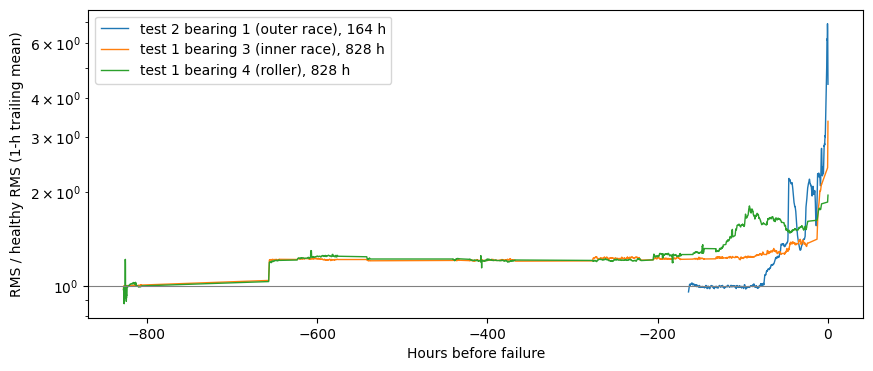

In [14]:
# ---- Colab cell 14: one record per bearing, on a common scale ----
# In plain words: each bearing becomes hours, true RUL, RMS and kurtosis. Each accelerometer
# reads a different level even when healthy, so RMS is divided by that bearing's own healthy
# level (median of its first 17 h): 1 = healthy, 2 = twice as rough. Kurtosis has no units
# and is kept as it is. Test 1 has gaps, so hours come from the file timestamps, not the
# snapshot count. The plot shows the three bearings against hours before failure.
HEALTHY_HOURS = 17
BEARINGS = {"test 2 bearing 1 (outer race)": (feat, 1),
            "test 1 bearing 3 (inner race)": (feat1, 5),
            "test 1 bearing 4 (roller)": (feat1, 7)}

def make_record(table, ch):
    """Hours, true RUL, healthy-normalised RMS and kurtosis for one channel."""
    t = table.dropna(subset=[f"rms_{ch}", f"kurtosis_{ch}"])
    times = file_times(t["file"])
    h = ((times - times.iloc[0]).dt.total_seconds() / 3600).to_numpy()
    r = t[f"rms_{ch}"].to_numpy()
    return {"hours": h, "rul": h[-1] - h,
            "rms": r / np.median(r[h < HEALTHY_HOURS]),
            "kurt": t[f"kurtosis_{ch}"].to_numpy()}

records = {name: make_record(tab, ch) for name, (tab, ch) in BEARINGS.items()}
plt.figure(figsize=(10, 4))
for name, r in records.items():
    plt.semilogy(-r["rul"], trailing_mean(r["rms"], 6), lw=1, label=f"{name}, {r['hours'][-1]:.0f} h")
plt.axhline(1, color="grey", lw=0.8)
plt.xlabel("Hours before failure")
plt.ylabel("RMS / healthy RMS (1-h trailing mean)")
plt.legend()
plt.show()

In [15]:
# ---- Colab cell 15: unseen-bearing test (train on test 2, tune on one test 1 bearing, test on the other) ----
# In plain words: the hardest and most honest exam. Every model learns only from test 2
# bearing 1 (outer race), picks its settings on one test 1 bearing and is scored once on the
# other, which it has never seen and which failed in a different way. Then the two test 1
# bearings swap roles. Test 1 ran about five times longer than test 2, so early in test 1 the
# true RUL is far beyond anything seen in training and every model is capped at 164 h. The
# "last" columns therefore also score just the final 164 h, the range the models were
# trained on, which is where a maintenance decision is actually made.
TRAIN = "test 2 bearing 1 (outer race)"
FOLDS = [("test 1 bearing 4 (roller)", "test 1 bearing 3 (inner race)"),   # (validate on, test on)
         ("test 1 bearing 3 (inner race)", "test 1 bearing 4 (roller)")]

rows1, preds1 = [], {}
for val_name, test_name in FOLDS:
    recs = [records[TRAIN], records[val_name], records[test_name]]
    roles = np.concatenate([np.full(r["hours"].size, role)
                            for r, role in zip(recs, ["train", "val", "test"])])
    rul_all = np.concatenate([r["rul"] for r in recs])
    feats = {sw: np.vstack([np.column_stack([trailing_mean(r["rms"], sw), trailing_mean(r["kurt"], sw)])
                            for r in recs]) for sw in SMOOTH}
    # threshold f x healthy is just f, because RMS is already divided by its healthy level
    extrap1 = {(sw, w, f): np.concatenate([extrapolate_rul_fast(r["hours"], trailing_mean(r["rms"], sw), f, w)
                                           for r in recs])
               for sw in SMOOTH for w in EXTRAP_HOURS for f in FAIL_FACTORS}
    test_rul = recs[2]["rul"]
    last = test_rul <= recs[0]["rul"].max()         # final 164 h of the test bearing

    results_here = []
    for name, life in {"catalogue L10": L10, "catalogue L50": L50}.items():
        cat = np.concatenate([catalogue_rul(r["hours"], life) for r in recs])
        results_here.append((name, *tune_fixed({name: cat}, rul_all, roles, cap=False)))
    results_here.append(("trend extrapolation", *tune_fixed(extrap1, rul_all, roles)))
    for name, (make, grid) in models.items():
        results_here.append((name, *tune_and_test(make, grid, feats, rul_all, roles)))

    for name, row, p in results_here:
        in_range = rul_scores(test_rul[last], p[last])
        chosen = {k: row[k] for k in ("smooth", "max_depth", "C", "settings") if k in row}
        rows1.append({"test on": test_name, "model": name, **chosen,
                      "MAE_h": row["MAE_h"], "late_%": row["late_%"],
                      "MAE_last_h": in_range["MAE_h"], "late_last_%": in_range["late_%"]})
        preds1[(test_name, name)] = p

results1 = pd.DataFrame(rows1)
display(results1.pivot_table(index="model", columns="test on",
                             values=["MAE_last_h", "late_last_%", "MAE_h"]).round(1))
results1.to_csv("/content/repo/data/rul_results_unseen_bearing.csv", index=False)

MAE_h                            \
test on             test 1 bearing 3 (inner race) test 1 bearing 4 (roller)   
model                                                                         
SVR                                         255.8                     263.6   
catalogue L10                               743.3                     743.3   
catalogue L50                              4687.8                    4687.8   
linear                                      240.5                     246.8   
mean (Dummy)                                246.6                     246.6   
tree                                        253.6                     259.5   
trend extrapolation                         206.5                     205.6   

                                       MAE_last_h                            \
test on             test 1 bearing 3 (inner race) test 1 bearing 4 (roller)   
model                                                                         
SVR                                          26.2                      47.8   
catalogue L10                               743.3                     743.3   
catalogue L50                              4687.8                    4687.8   
linear                                       30.5                      46.1   
mean (Dummy)                                 34.9                      34.9   
tree                                         32.1                      54.1   
trend extrapolation                          74.3                      62.2   

                                      late_last_%                            
test on             test 1 bearing 3 (inner race) test 1 bearing 4 (roller)  
model                                                                        
SVR                                          14.0                      11.1  
catalogue L10                               100.0                     100.0  
catalogue L50                               100.0                     100.0  
linear                                       50.5                      35.1  
mean (Dummy)                                 47.2                      47.2  
tree                                         28.0                       8.6  
trend extrapolation                         100.0                      63.0

,"test 2, time split","unseen bearing, last 164 h"
model,,
mean (Dummy),98.3,34.9
SVR,79.8,37.0
linear,14.8,38.3
tree,49.1,43.1
trend extrapolation,51.0,68.3
catalogue L10,1407.0,743.3
catalogue L50,5351.5,4687.8


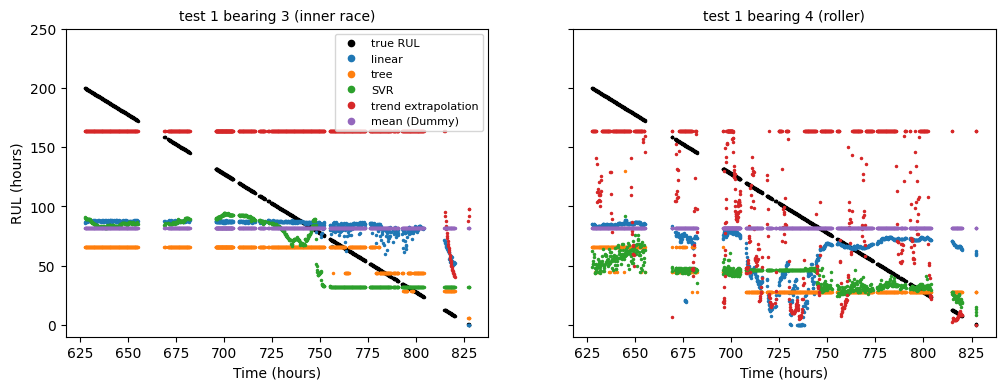

In [16]:
# ---- Colab cell 16: does the test 2 ranking hold on unseen bearings? ----
# In plain words: left, the test 2 time-split error (cell 7) next to the unseen-bearing error
# in the final 164 h (mean of the two test 1 bearings). A model that stays good on both is
# the one to recommend. Right, the predictions against the truth over the last 200 h of
# each test 1 bearing (black = true RUL; dots above it are late).
compare = pd.DataFrame({
    "test 2, time split": results[results["method"] == "time"].set_index("model")["MAE_h"],
    "unseen bearing, last 164 h": results1.groupby("model")["MAE_last_h"].mean()})
display(compare.sort_values("unseen bearing, last 164 h").round(1))

fig, axes = plt.subplots(1, len(FOLDS), figsize=(12, 4), sharey=True)
for ax, (_, test_name) in zip(axes, FOLDS):
    r = records[test_name]
    near = r["rul"] <= 200
    ax.plot(r["hours"][near], r["rul"][near], "k.", ms=3, label="true RUL")
    for name in ["linear", "tree", "SVR", "trend extrapolation", "mean (Dummy)"]:
        ax.plot(r["hours"][near], preds1[(test_name, name)][near], ".", ms=3, label=name)
    ax.set_title(test_name, fontsize=10)
    ax.set_xlabel("Time (hours)")
axes[0].set_ylabel("RUL (hours)")
axes[0].set_ylim(-10, 250)
axes[0].legend(fontsize=8, markerscale=3)
plt.show()

In [17]:
# ---- Colab cell 17: train on two bearings, test on the third (leave one bearing out) ----
# In plain words: cell 15 learned from one bearing only. Here each model learns from two
# bearings and is tested on the third, which it never saw, in turn for all three. Settings
# are chosen without the test bearing: fit on one training bearing, check on the other,
# swap, and keep the setting with the lowest average error. Now the models have seen two
# failure modes and two very different life lengths, so the question is whether more
# failure histories make the vibration models beat the "know nothing" Dummy.
# Uses the new functions in rul_models.py (copy it into src/ and restart if the import fails).
from rul_models import leave_one_out_by_group, fixed_leave_one_out_by_group

names = list(records)
y_by = {n: records[n]["rul"] for n in names}
feat_by = {n: {sw: np.column_stack([trailing_mean(records[n]["rms"], sw),
                                    trailing_mean(records[n]["kurt"], sw)]) for sw in SMOOTH}
           for n in names}
extrap_by = {(sw, w, f): {n: extrapolate_rul_fast(records[n]["hours"], trailing_mean(records[n]["rms"], sw), f, w)
                          for n in names}
             for sw in SMOOTH for w in EXTRAP_HOURS for f in FAIL_FACTORS}

rows2, preds2 = [], {}
for test_name in names:
    found = []
    for name, life in {"catalogue L10": L10, "catalogue L50": L50}.items():
        cat = {n: catalogue_rul(records[n]["hours"], life) for n in names}
        found.append((name, *fixed_leave_one_out_by_group({name: cat}, y_by, test_name, cap=False)))
    found.append(("trend extrapolation", *fixed_leave_one_out_by_group(extrap_by, y_by, test_name)))
    for name, (make, grid) in models.items():
        found.append((name, *leave_one_out_by_group(make, grid, feat_by, y_by, test_name)))
    last = y_by[test_name] <= 164                     # final 164 h, comparable with cell 15
    for name, row, p in found:
        in_range = rul_scores(y_by[test_name][last], p[last])
        chosen = {k: row[k] for k in ("smooth", "max_depth", "C", "settings") if k in row}
        rows2.append({"test on": test_name, "model": name, **chosen,
                      "MAE_h": row["MAE_h"], "late_%": row["late_%"],
                      "MAE_last_h": in_range["MAE_h"], "late_last_%": in_range["late_%"]})
        preds2[(test_name, name)] = p

results2 = pd.DataFrame(rows2)
display(results2.pivot_table(index="model", columns="test on",
                             values=["MAE_h", "MAE_last_h", "late_last_%"]).round(1))
results2.to_csv("/content/repo/data/rul_results_leave_one_bearing_out.csv", index=False)

MAE_h                            \
test on             test 1 bearing 3 (inner race) test 1 bearing 4 (roller)   
model                                                                         
SVR                                         193.7                     188.2   
catalogue L10                               743.3                     743.3   
catalogue L50                              4687.8                    4687.8   
linear                                      181.7                     172.4   
mean (Dummy)                                192.2                     192.2   
tree                                        169.4                     155.1   
trend extrapolation                         356.7                     353.8   

                                                   \
test on             test 2 bearing 1 (outer race)   
model                                               
SVR                                         434.1   
catalogue L10                              1407.0   
catalogue L50                              5351.5   
linear                                      334.1   
mean (Dummy)                                235.8   
tree                                        441.9   
trend extrapolation                         347.4   

                                       MAE_last_h                            \
test on             test 1 bearing 3 (inner race) test 1 bearing 4 (roller)   
model                                                                         
SVR                                          73.3                      50.2   
catalogue L10                               743.3                     743.3   
catalogue L50                              4687.8                    4687.8   
linear                                      154.4                     114.6   
mean (Dummy)                                159.1                     159.1   
tree                                        144.7                      35.6   
trend extrapolation                         414.3                     362.5   

                                                   \
test on             test 2 bearing 1 (outer race)   
model                                               
SVR                                         434.1   
catalogue L10                              1407.0   
catalogue L50                              5351.5   
linear                                      334.1   
mean (Dummy)                                235.8   
tree                                        441.9   
trend extrapolation                         347.4   

                                      late_last_%                            \
test on             test 1 bearing 3 (inner race) test 1 bearing 4 (roller)   
model                                                                         
SVR                                         100.0                      60.2   
catalogue L10                               100.0                     100.0   
catalogue L50                               100.0                     100.0   
linear                                       99.4                      95.8   
mean (Dummy)                                100.0                     100.0   
tree                                         97.4                      42.3   
trend extrapolation                          80.3                      59.9   

                                                   
test on             test 2 bearing 1 (outer race)  
model                                              
SVR                                          79.4  
catalogue L10                               100.0  
catalogue L50                               100.0  
linear                                       75.0  
mean (Dummy)                                100.0  
tree                                         85.8  
trend extrapolation                          65.9

In [18]:
# ---- Colab cell 18: one bearing vs two bearings of training ----
# In plain words: did a second training bearing help? Mean error in the final 164 h over the
# test 1 bearings, trained on one bearing (cell 15) and on two (cell 17), plus the
# leave-one-out result on test 2 bearing 1, which now has to be predicted from test 1 only.
t1 = [n for n in names if n.startswith("test 1")]
summary2 = pd.DataFrame({
    "1 training bearing (test 1, last 164 h)": results1.groupby("model")["MAE_last_h"].mean(),
    "2 training bearings (test 1, last 164 h)": results2[results2["test on"].isin(t1)]
        .groupby("model")["MAE_last_h"].mean(),
    "2 training bearings (test 2 b1, whole run)": results2[results2["test on"] == TRAIN]
        .set_index("model")["MAE_h"],
    "late %, 2 bearings (mean, last 164 h)": results2.groupby("model")["late_last_%"].mean()})
display(summary2.sort_values("2 training bearings (test 1, last 164 h)").round(1))
summary2.round(2).to_csv("/content/repo/data/rul_training_bearings_summary.csv")

,"1 training bearing (test 1, last 164 h)","2 training bearings (test 1, last 164 h)","2 training bearings (test 2 b1, whole run)","late %, 2 bearings (mean, last 164 h)"
model,,,,
SVR,37.0,61.7,434.1,79.9
tree,43.1,90.2,441.9,75.1
linear,38.3,134.5,334.1,90.1
mean (Dummy),34.9,159.1,235.8,100.0
trend extrapolation,68.3,388.4,347.4,68.7
catalogue L10,743.3,743.3,1407.0,100.0
catalogue L50,4687.8,4687.8,5351.5,100.0


,test on,model,margin_h,MAE_last_h before,MAE_last_h after,late_last_% before,late_last_% after
0,test 2 bearing 1 (outer race),linear,262.1,334.1,147.0,75.0,69.4
1,test 2 bearing 1 (outer race),tree,116.5,441.9,367.2,85.8,65.3
2,test 2 bearing 1 (outer race),SVR,135.4,434.1,342.4,79.4,64.8
3,test 1 bearing 3 (inner race),linear,475.5,154.4,84.7,99.4,0.0
4,test 1 bearing 3 (inner race),tree,336.7,144.7,84.7,97.4,0.0
5,test 1 bearing 3 (inner race),SVR,240.7,73.3,84.7,100.0,0.0
6,test 1 bearing 4 (roller),linear,341.2,114.6,84.7,95.8,0.0
7,test 1 bearing 4 (roller),tree,425.1,35.6,84.7,42.3,0.0
8,test 1 bearing 4 (roller),SVR,263.0,50.2,84.7,60.2,0.0


,margin_h,MAE_last_h before,MAE_last_h after,late_last_% before,late_last_% after
model,,,,,
SVR,213.0,185.8,170.6,79.9,21.6
linear,359.6,201.0,105.5,90.1,23.1
tree,292.8,207.4,178.9,75.1,21.8


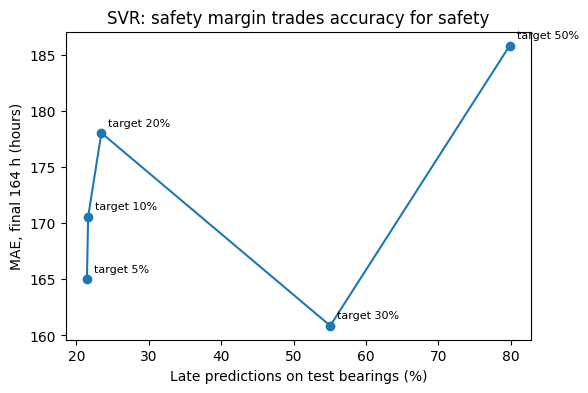

In [19]:
# ---- Colab cell 19: safety margin for late predictions (calibrated on validation only) ----
# In plain words: most predictions on new bearings were late (the bearing fails before the
# planned replacement). A safety margin subtracts a fixed number of hours from every
# prediction, like planning to arrive early. The margin is set on the validation bearings
# (the inner swaps of cell 17, never the test bearing) so that only LATE_TARGET of the
# validation predictions stay late. It then goes onto the test bearing unchanged. Expect
# fewer late predictions but a larger average error: earlier replacements cost some life.
# The plot shows that trade-off for SVR as the late target is tightened.
from rul_models import safety_margin, apply_margin, inner_validation_predictions

LATE_TARGET = 0.1                      # accept 10 % late predictions on validation
TARGETS = [0.5, 0.3, 0.2, 0.1, 0.05]   # for the trade-off plot
KNOBS = {"linear": ["smooth"], "tree": ["smooth", "max_depth"], "SVR": ["smooth", "C"]}

def chosen_settings(name, test_name):
    """Settings cell 17 chose for this model and test bearing."""
    row = results2[(results2["model"] == name) & (results2["test on"] == test_name)].iloc[0]
    return {k: int(row[k]) if k in ("smooth", "max_depth") else float(row[k]) for k in KNOBS[name]}

rows3, curve = [], []
for test_name in names:
    last = y_by[test_name] <= 164
    for name in KNOBS:
        make = models[name][0]
        val_true, val_pred = inner_validation_predictions(make, chosen_settings(name, test_name),
                                                          feat_by, y_by, test_name)
        raw = preds2[(test_name, name)]
        for target in TARGETS:
            m = safety_margin(val_true, val_pred, target)
            p = apply_margin(raw, m)
            s = rul_scores(y_by[test_name][last], p[last])
            curve.append({"test on": test_name, "model": name, "target_%": 100 * target,
                          "margin_h": m, "MAE_last_h": s["MAE_h"], "late_last_%": s["late_%"]})
        m = safety_margin(val_true, val_pred, LATE_TARGET)
        before = rul_scores(y_by[test_name][last], raw[last])
        after = rul_scores(y_by[test_name][last], apply_margin(raw, m)[last])
        rows3.append({"test on": test_name, "model": name, "margin_h": m,
                      "MAE_last_h before": before["MAE_h"], "MAE_last_h after": after["MAE_h"],
                      "late_last_% before": before["late_%"], "late_last_% after": after["late_%"]})

margins = pd.DataFrame(rows3)
display(margins.round(1))
display(margins.groupby("model").mean(numeric_only=True).round(1))
margins.to_csv("/content/repo/data/rul_safety_margin.csv", index=False)

curve = pd.DataFrame(curve)
svr = curve[curve["model"] == "SVR"].groupby("target_%")[["MAE_last_h", "late_last_%"]].mean()
plt.figure(figsize=(6, 4))
plt.plot(svr["late_last_%"], svr["MAE_last_h"], "o-")
for t, r in svr.iterrows():
    plt.annotate(f"target {t:.0f}%", (r["late_last_%"], r["MAE_last_h"]), fontsize=8,
                 xytext=(5, 5), textcoords="offset points")
plt.xlabel("Late predictions on test bearings (%)")
plt.ylabel("MAE, final 164 h (hours)")
plt.title("SVR: safety margin trades accuracy for safety")
plt.show()

6324 snapshots


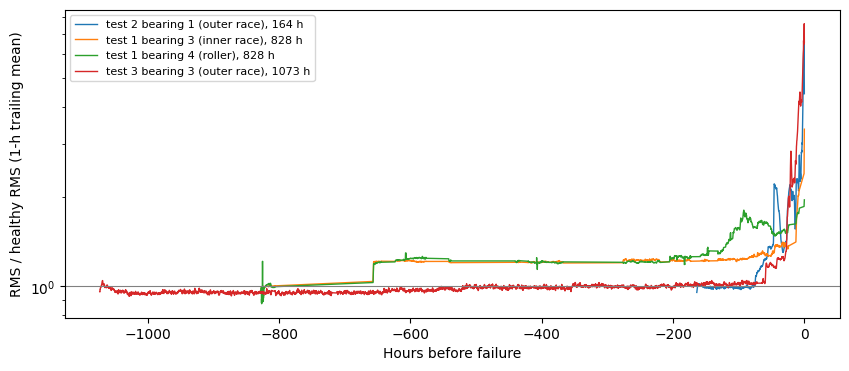

In [23]:
# ---- Colab cell 20: add test 3 bearing 3 (outer race) as a fourth bearing ----
# In plain words: the same record as cell 14 (hours, true RUL, RMS / healthy RMS, kurtosis)
# for the fourth bearing. Test 3 has 4 channels, one per bearing, so bearing 3 is channel 3.
# Needs data/features_3rd_test.csv from the Main.ipynb test 3 cell.
feat3 = pd.read_csv("/content/repo/data/features_3rd_test.csv", index_col=0)
print(len(feat3), "snapshots")                              # expect about 6324
assert len(feat3) > 6000, "partial test 3 table: run the test 3 cell in Main.ipynb and publish"
records4 = dict(records)
records4["test 3 bearing 3 (outer race)"] = make_record(feat3, 3)

plt.figure(figsize=(10, 4))
for name, r in records4.items():
    plt.semilogy(-r["rul"], trailing_mean(r["rms"], 6), lw=1, label=f"{name}, {r['hours'][-1]:.0f} h")
plt.axhline(1, color="grey", lw=0.8)
plt.xlabel("Hours before failure")
plt.ylabel("RMS / healthy RMS (1-h trailing mean)")
plt.legend(fontsize=8)
plt.show()

In [24]:
# ---- Colab cell 21: train on three bearings, test on the fourth (leave one bearing out) ----
# In plain words: cell 17 again, now with four bearings, so every model learns from three
# failure histories. Settings are still chosen without the test bearing (each training
# bearing is held out in turn). Results go to a new file; cell 17's file is not touched.
def leave_one_bearing_out(recs):
    """Cell 17 for any set of bearing records: results table and predictions."""
    names_ = list(recs)
    y_ = {n: recs[n]["rul"] for n in names_}
    feat_ = {n: {sw: np.column_stack([trailing_mean(recs[n]["rms"], sw),
                                      trailing_mean(recs[n]["kurt"], sw)]) for sw in SMOOTH}
             for n in names_}
    extrap_ = {(sw, w, f): {n: extrapolate_rul_fast(recs[n]["hours"], trailing_mean(recs[n]["rms"], sw), f, w)
                            for n in names_}
               for sw in SMOOTH for w in EXTRAP_HOURS for f in FAIL_FACTORS}
    rows, preds_ = [], {}
    for test_name in names_:
        found = []
        for name, life in {"catalogue L10": L10, "catalogue L50": L50}.items():
            cat = {n: catalogue_rul(recs[n]["hours"], life) for n in names_}
            found.append((name, *fixed_leave_one_out_by_group({name: cat}, y_, test_name, cap=False)))
        found.append(("trend extrapolation", *fixed_leave_one_out_by_group(extrap_, y_, test_name)))
        for name, (make, grid) in models.items():
            found.append((name, *leave_one_out_by_group(make, grid, feat_, y_, test_name)))
        last = y_[test_name] <= 164                         # final 164 h, as in cells 15-17
        for name, row, p in found:
            in_range = rul_scores(y_[test_name][last], p[last])
            chosen = {k: row[k] for k in ("smooth", "max_depth", "C", "settings") if k in row}
            rows.append({"test on": test_name, "model": name, **chosen,
                         "MAE_h": row["MAE_h"], "late_%": row["late_%"],
                         "MAE_last_h": in_range["MAE_h"], "late_last_%": in_range["late_%"]})
            preds_[(test_name, name)] = p
    return pd.DataFrame(rows), preds_

start = time.perf_counter()
results4, preds4 = leave_one_bearing_out(records4)
print(f"{time.perf_counter() - start:.0f} s")
display(results4.pivot_table(index="model", columns="test on",
                             values=["MAE_last_h", "late_last_%"]).round(1))
results4.to_csv("/content/repo/data/rul_results_four_bearings.csv", index=False)

314 s


MAE_last_h                            \
test on             test 1 bearing 3 (inner race) test 1 bearing 4 (roller)   
model                                                                         
SVR                                         114.1                      39.1   
catalogue L10                               743.3                     743.3   
catalogue L50                              4687.8                    4687.8   
linear                                      195.3                     111.0   
mean (Dummy)                                355.5                     355.5   
tree                                        177.7                     184.1   
trend extrapolation                         529.6                     468.6   

                                                   \
test on             test 2 bearing 1 (outer race)   
model                                               
SVR                                         279.5   
catalogue L10                              1407.0   
catalogue L50                              5351.5   
linear                                      306.5   
mean (Dummy)                                366.6   
tree                                        591.9   
trend extrapolation                         449.8   

                                                   \
test on             test 3 bearing 3 (outer race)   
model                                               
SVR                                         110.7   
catalogue L10                               497.6   
catalogue L50                              4442.1   
linear                                      201.7   
mean (Dummy)                                191.4   
tree                                        216.8   
trend extrapolation                         366.7   

                                      late_last_%                            \
test on             test 1 bearing 3 (inner race) test 1 bearing 4 (roller)   
model                                                                         
SVR                                         100.0                       7.9   
catalogue L10                               100.0                     100.0   
catalogue L50                               100.0                     100.0   
linear                                       97.1                      72.3   
mean (Dummy)                                100.0                     100.0   
tree                                        100.0                     100.0   
trend extrapolation                          80.3                      59.9   

                                                   \
test on             test 2 bearing 1 (outer race)   
model                                               
SVR                                          99.9   
catalogue L10                               100.0   
catalogue L50                               100.0   
linear                                       90.3   
mean (Dummy)                                100.0   
tree                                         89.2   
trend extrapolation                          65.9   

                                                   
test on             test 3 bearing 3 (outer race)  
model                                              
SVR                                          97.5  
catalogue L10                               100.0  
catalogue L50                               100.0  
linear                                       90.9  
mean (Dummy)                                100.0  
tree                                        100.0  
trend extrapolation                          68.6

,2 training bearings (mean of 3),3 training bearings (same 3),3 training bearings (test 3 b3),"late %, 3 bearings (mean of 4)"
model,,,,
SVR,185.8,144.2,110.7,76.3
linear,201.0,204.3,201.7,87.6
tree,207.4,317.9,216.8,97.3
mean (Dummy),184.7,359.2,191.4,100.0
trend extrapolation,374.7,482.7,366.7,68.7
catalogue L10,964.6,964.6,497.6,100.0
catalogue L50,4909.0,4909.0,4442.1,100.0


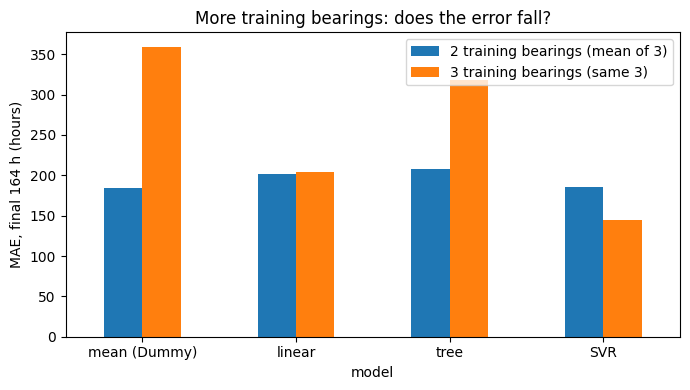

In [25]:
# ---- Colab cell 22: did a third training bearing help? ----
# In plain words: for the three original bearings, the error in their final 164 h when the
# models learned from two bearings (cell 17) and from three (cell 21). Lower is better.
# The last column is the new test 3 bearing, predicted from the other three.
compare = pd.DataFrame({
    "2 training bearings (mean of 3)": results2.groupby("model")["MAE_last_h"].mean(),
    "3 training bearings (same 3)": results4[results4["test on"].isin(names)]
        .groupby("model")["MAE_last_h"].mean(),
    "3 training bearings (test 3 b3)": results4[~results4["test on"].isin(names)]
        .set_index("model")["MAE_last_h"],
    "late %, 3 bearings (mean of 4)": results4.groupby("model")["late_last_%"].mean()})
display(compare.sort_values("3 training bearings (same 3)").round(1))
compare.round(2).to_csv("/content/repo/data/rul_training_bearings_summary_4.csv")

ml = ["mean (Dummy)", "linear", "tree", "SVR"]
compare.loc[ml, ["2 training bearings (mean of 3)", "3 training bearings (same 3)"]].plot.bar(figsize=(7, 4))
plt.ylabel("MAE, final 164 h (hours)")
plt.title("More training bearings: does the error fall?")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
MSG = "updating and refining"   # edit this each time
NB = "Data Analysis.ipynb"
%cd /content/repo
!mkdir -p notebooks && cp "/content/drive/MyDrive/Colab Notebooks/{NB}" notebooks/
!pdoc --math ./src/*.py -o ./docs
!PYTHONPATH=src pytest tests -v > test_report.txt
!git add -A
!git commit -m "{MSG}"
!git pull --rebase -X theirs origin main
!git push origin main

/content/repo
[main be84632] updating and refining
 2 files changed, 2 insertions(+), 2 deletions(-)
remote: Enumerating objects: 17, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 12 (delta 8), reused 10 (delta 6), pack-reused 0 (from 0)
Unpacking objects: 100% (12/12), 38.49 KiB | 414.00 KiB/s, done.
From https://github.com/Ryan-T-Monash/MMA3001-Project
 * branch            main       -> FETCH_HEAD
   e2b8fd5..e2e72b7  main       -> origin/main
Successfully rebased and updated refs/heads/main.
Enumerating objects: 9, done.
Counting objects: 100% (9/9), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (5/5), 613 bytes | 613.00 KiB/s, done.
Total 5 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/Ryan-T-Monash/MMA3001-Project.git
   e2e72b7..824bc49  main -> main
